In [ ]:
from google.colab import files
files.upload()

Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"saakash20","key":"65f4578fec62955b36c2d868323692b1"}'}

In [ ]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/kaggle.json
!chmod 600 ~/.kaggle/kaggle.json

In [ ]:
!pip install -q kaggle

In [ ]:
!kaggle datasets download -d joebeachcapital/customer-segmentation

Dataset URL: https://www.kaggle.com/datasets/joebeachcapital/customer-segmentation
License(s): DbCL-1.0
100% 1.55k/1.55k [00:00<00:00, 4.65MB/s]



In [ ]:
# Numerical operations
import numpy as np

# Data manipulation
import pandas as pd

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

# Ignore warnings
import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
# Extract the dataset
!unzip -o customer-segmentation.zip -d /content/customer_segmentation

# Load the CSV file
df = pd.read_csv('/content/customer_segmentation/Mall_Customers.csv')

# Display first 5 rows
df.head()

Archive:  customer-segmentation.zip
  inflating: /content/customer_segmentation/Mall_Customers.csv  


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [ ]:
# Dataset shape
print("Shape:", df.shape)

# Column names
print("\nColumns:", df.columns.tolist())

# Dataset information
df.info()

# Statistical summary
display(df.describe())

# Missing values
print("\nMissing Values:\n", df.isnull().sum())

# Duplicate records
print("\nDuplicate Rows:", df.duplicated().sum())

Shape: (200, 5)

Columns: ['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000



Missing Values:
 CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Duplicate Rows: 0


In [ ]:
# Check duplicate rows
print("Duplicates:", df.duplicated().sum())

# Remove duplicates
df.drop_duplicates(inplace=True)

# Check missing values
print("\nMissing Values:\n", df.isnull().sum())

# Fill missing numerical values with median
for col in df.select_dtypes(include=np.number).columns:
    df[col] = df[col].fillna(df[col].median())

# Fill missing categorical values with mode
for col in df.select_dtypes(include='object').columns:
    if df[col].isnull().any():
        df[col] = df[col].fillna(df[col].mode()[0])

# Verify cleaned data
print("\nRemaining Missing Values:\n", df.isnull().sum())
print("\nFinal Shape:", df.shape)

Duplicates: 0

Missing Values:
 CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Remaining Missing Values:
 CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Final Shape: (200, 5)


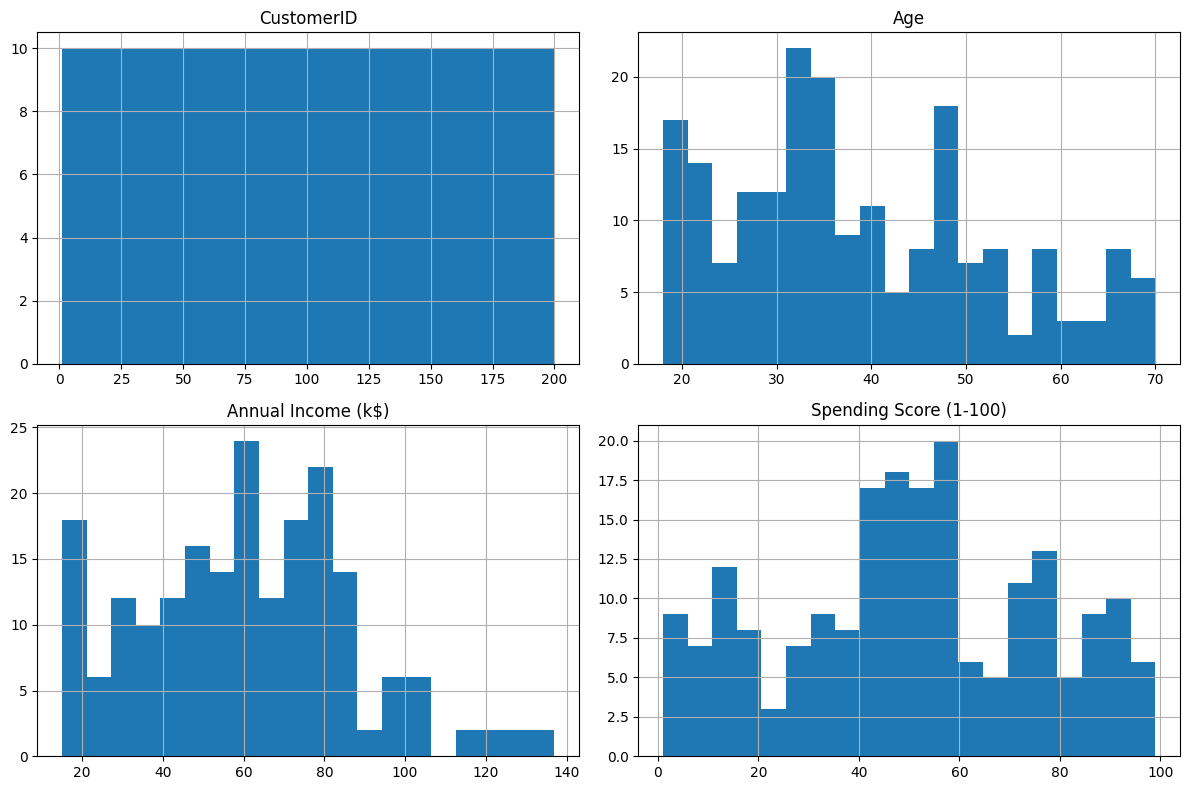

In [ ]:
df.hist(figsize=(12, 8), bins=20)
plt.tight_layout()
plt.show()

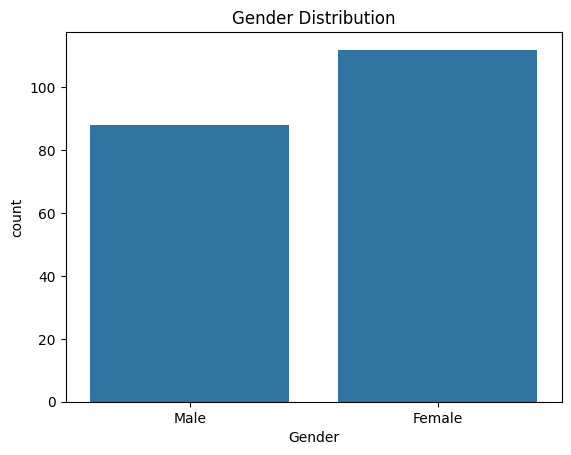

In [ ]:
sns.countplot(x='Gender', data=df)
plt.title('Gender Distribution')
plt.show()

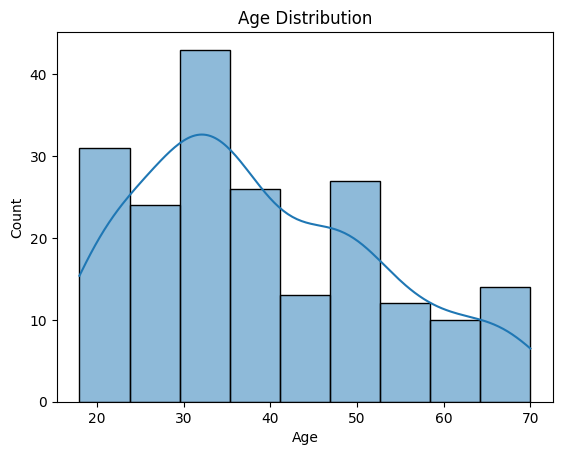

In [ ]:
sns.histplot(df['Age'], kde=True)
plt.title('Age Distribution')
plt.show()

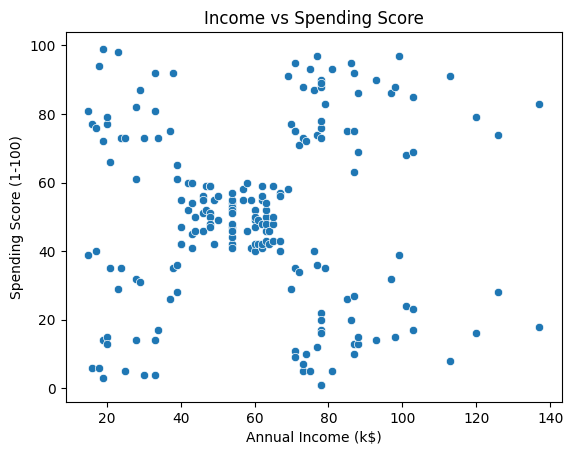

In [ ]:
sns.scatterplot(
    x='Annual Income (k$)',
    y='Spending Score (1-100)',
    data=df
)
plt.title('Income vs Spending Score')
plt.show()

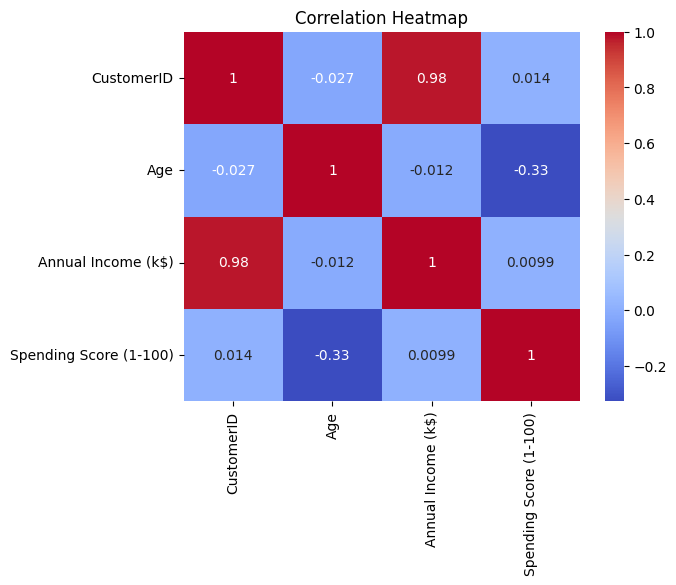

In [ ]:
sns.heatmap(df.select_dtypes(include=np.number).corr(),
            annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

Step 7: Feature Selection and Feature Scaling ⚙️
In this step, we select the important features and scale them for K-Means clustering.

In [ ]:
# Select relevant features
X = df[['Annual Income (k$)', 'Spending Score (1-100)']]

X.head()

,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


In [ ]:
# Standardize the features
scaler = StandardScaler()

scaled_data = scaler.fit_transform(X)

print("Feature scaling completed!")
print("Shape:", scaled_data.shape)

Feature scaling completed!
Shape: (200, 2)


In [ ]:
scaled_df = pd.DataFrame(
    scaled_data,
    columns=X.columns
)

scaled_df.head()

,Annual Income (k$),Spending Score (1-100)
0,-1.738999,-0.434801
1,-1.738999,1.195704
2,-1.700830,-1.715913
3,-1.700830,1.040418
4,-1.662660,-0.395980


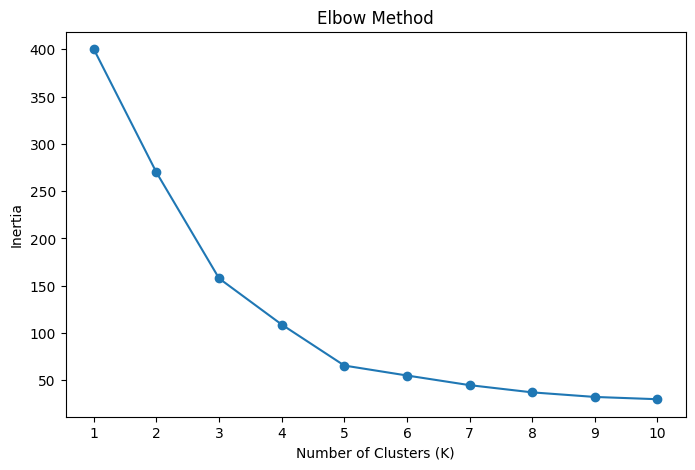

In [ ]:
# Calculate inertia for different K values
inertia_values = []

K_range = range(1, 11)

for k in K_range:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeans.fit(scaled_data)
    inertia_values.append(kmeans.inertia_)

# Plot the Elbow Curve
plt.figure(figsize=(8, 5))
plt.plot(K_range, inertia_values, marker='o')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.title('Elbow Method')
plt.xticks(K_range)
plt.show()

K = 2, Silhouette Score = 0.3213
K = 3, Silhouette Score = 0.4666
K = 4, Silhouette Score = 0.4939
K = 5, Silhouette Score = 0.5547
K = 6, Silhouette Score = 0.5399
K = 7, Silhouette Score = 0.5281
K = 8, Silhouette Score = 0.4552
K = 9, Silhouette Score = 0.4571
K = 10, Silhouette Score = 0.4432


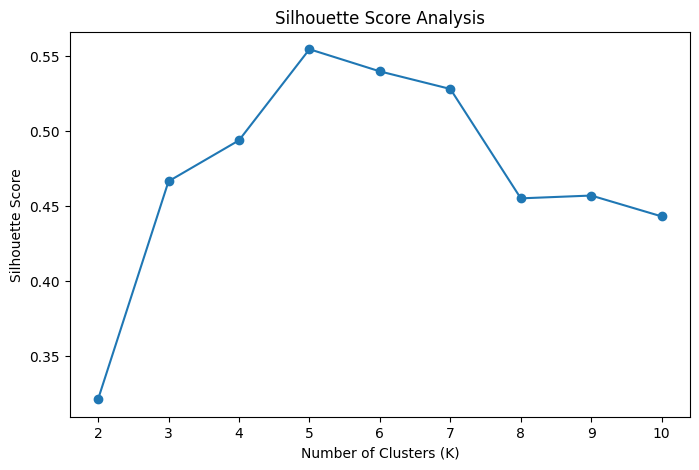

In [ ]:
# Calculate Silhouette Scores
silhouette_scores = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(scaled_data)
    score = silhouette_score(scaled_data, labels)
    silhouette_scores.append(score)

    print(f"K = {k}, Silhouette Score = {score:.4f}")

# Plot scores
plt.figure(figsize=(8, 5))
plt.plot(range(2, 11), silhouette_scores, marker='o')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score Analysis')
plt.xticks(range(2, 11))
plt.show()

In [ ]:
# Set number of clusters
optimal_k = 5

# Train K-Means model
kmeans = KMeans(
    n_clusters=optimal_k,
    init='k-means++',
    random_state=42,
    n_init=10
)

# Assign cluster labels
cluster_labels = kmeans.fit_predict(scaled_data)

# Add clusters to the original dataset
df['Cluster'] = cluster_labels

print("K-Means model trained successfully!")

# Display results
display(df.head())

K-Means model trained successfully!


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,4
1,2,Male,21,15,81,2
2,3,Female,20,16,6,4
3,4,Female,23,16,77,2
4,5,Female,31,17,40,4


Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64


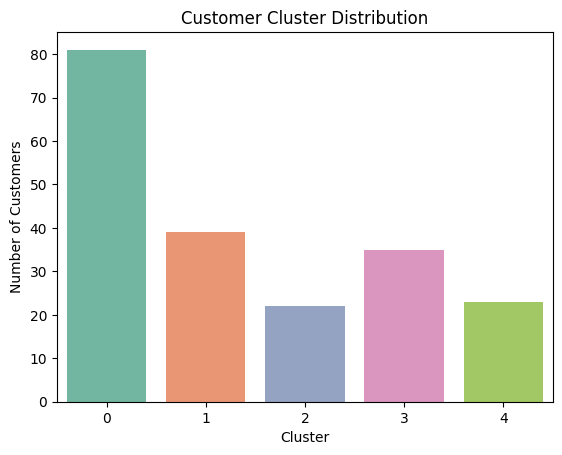

In [ ]:
# Count customers in each cluster
print(df['Cluster'].value_counts().sort_index())

# Visualize cluster distribution
sns.countplot(x='Cluster', data=df, hue='Cluster', palette='Set2', legend=False)

plt.title('Customer Cluster Distribution')
plt.xlabel('Cluster')
plt.ylabel('Number of Customers')
plt.show()

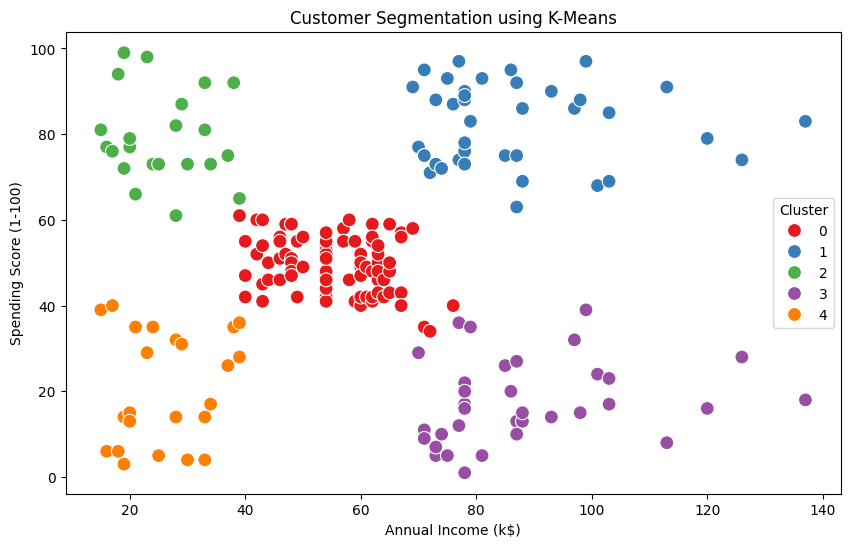

In [ ]:
# Plot customer clusters
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='Annual Income (k$)',
    y='Spending Score (1-100)',
    hue='Cluster',
    palette='Set1',
    s=100
)

plt.title('Customer Segmentation using K-Means')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend(title='Cluster')
plt.show()

Visualize Cluster Centroids 🎯

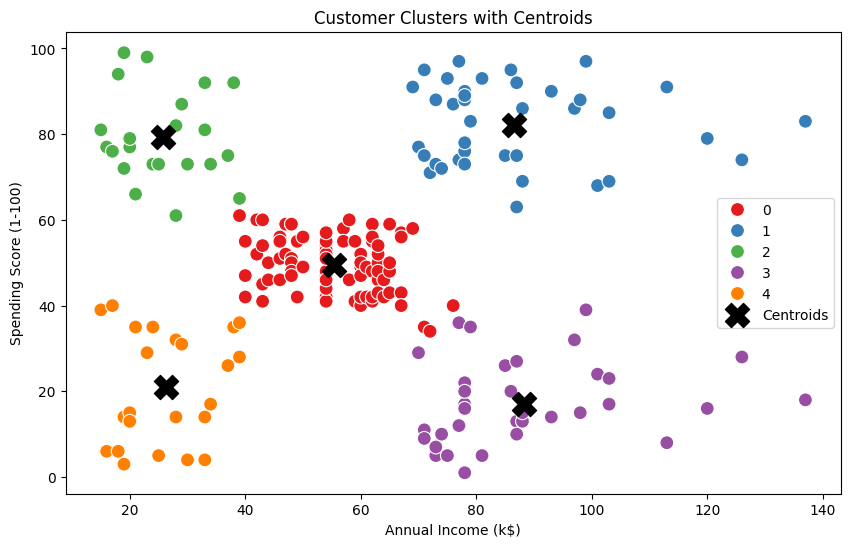

In [ ]:
# Get centroids in original feature scale
centroids = scaler.inverse_transform(kmeans.cluster_centers_)

# Plot clusters
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='Annual Income (k$)',
    y='Spending Score (1-100)',
    hue='Cluster',
    palette='Set1',
    s=100
)

# Plot centroids
plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    s=300,
    c='black',
    marker='X',
    label='Centroids'
)

plt.title('Customer Clusters with Centroids')
plt.legend()
plt.show()

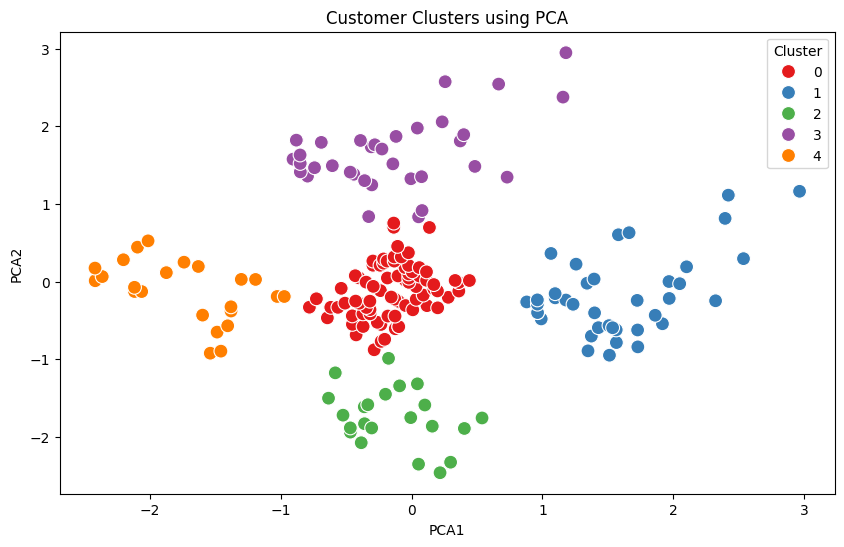

Explained variance ratio: [0.50495142 0.49504858]
Total variance explained: 1.0


In [ ]:
# Apply PCA
pca = PCA(n_components=2)

pca_data = pca.fit_transform(scaled_data)

# Create DataFrame
pca_df = pd.DataFrame(
    pca_data,
    columns=['PCA1', 'PCA2']
)

pca_df['Cluster'] = cluster_labels

# Visualize PCA clusters
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=pca_df,
    x='PCA1',
    y='PCA2',
    hue='Cluster',
    palette='Set1',
    s=100
)

plt.title('Customer Clusters using PCA')
plt.show()

# Explained variance
print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total variance explained:", pca.explained_variance_ratio_.sum())

In [ ]:
# Calculate average characteristics of each cluster
cluster_summary = df.groupby('Cluster')[
    ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']
].mean().round(2)

display(cluster_summary)

,Age,Annual Income (k$),Spending Score (1-100)
Cluster,,,
0,42.72,55.30,49.52
1,32.69,86.54,82.13
2,25.27,25.73,79.36
3,41.11,88.20,17.11
4,45.22,26.30,20.91


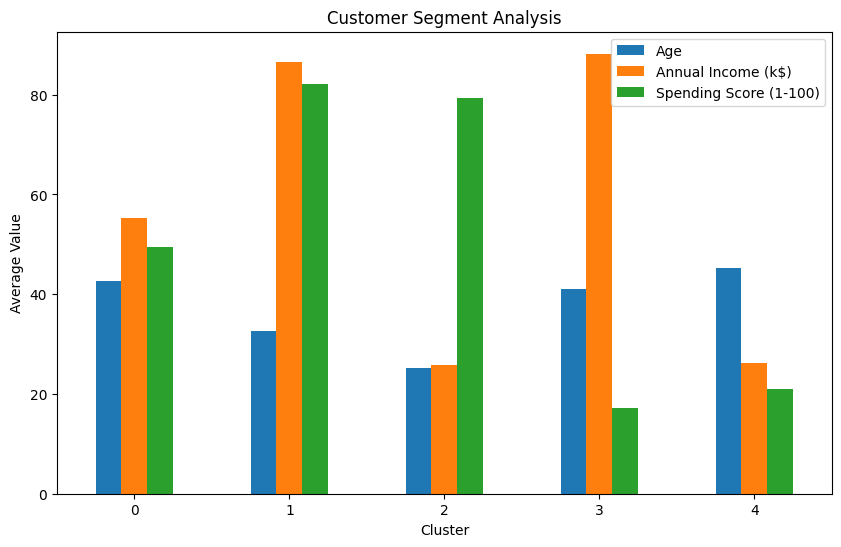

In [ ]:
cluster_summary.plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Customer Segment Analysis')
plt.ylabel('Average Value')
plt.xticks(rotation=0)
plt.show()

In [ ]:
# Save clustered dataset
df.to_csv('customer_segments.csv', index=False)

print("Dataset saved successfully!")

Dataset saved successfully!


In [ ]:
from google.colab import files

files.download('customer_segments.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Assign Customer Segment Names

In [ ]:
# Calculate average income and spending for each cluster
summary = df.groupby('Cluster')[
    ['Annual Income (k$)', 'Spending Score (1-100)']
].mean()

# Assign business labels
def label_cluster(row):
    income = row['Annual Income (k$)']
    spending = row['Spending Score (1-100)']

    if income >= summary['Annual Income (k$)'].median() and spending >= summary['Spending Score (1-100)'].median():
        return 'High-Value Customers'
    elif income >= summary['Annual Income (k$)'].median() and spending < summary['Spending Score (1-100)'].median():
        return 'High-Income, Low-Spending'
    elif income < summary['Annual Income (k$)'].median() and spending >= summary['Spending Score (1-100)'].median():
        return 'Low-Income, High-Spending'
    else:
        return 'Low-Income, Low-Spending'

cluster_names = {
    cluster: label_cluster(row)
    for cluster, row in summary.iterrows()
}

df['Segment'] = df['Cluster'].map(cluster_names)

# Display results
display(df[['Cluster', 'Segment']].drop_duplicates().sort_values('Cluster'))

,Cluster,Segment
43,0,High-Value Customers
123,1,High-Value Customers
1,2,"Low-Income, High-Spending"
124,3,"High-Income, Low-Spending"
0,4,"Low-Income, Low-Spending"
